<a href="https://colab.research.google.com/github/isurika23/EN4554_Deep-Learning-for-Vision/blob/main/EN4554_Assignment02_CNN/EN4554_Assignment02_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Setup


## Imports and Seeds

In [1]:
import os
import random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

# fix random seeds
def set_seed(seed=42):
    random.seed(seed);
    np.random.seed(seed)
    torch.manual_seed(seed);
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


#  Dataset destination
Option 1: Google drive (Google Colab)

In [2]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/EN4554_A2'
NUM_WORKERS = 2

Mounted at /content/drive


Option 2: root (Local machine) *-- currently commented*

In [ ]:
# PROJECT_DIR = '.'          # folder where this notebook lives
# NUM_WORKERS = 2            # on Windows, set to 0 if the DataLoader hangs or errors

In [3]:
DATA_ROOT   = os.path.join(PROJECT_DIR, 'data')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')   # save losses/accuracies here later
os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Data:", DATA_ROOT, "| Results:", RESULTS_DIR)

Data: /content/drive/MyDrive/EN4554_A2/data | Results: /content/drive/MyDrive/EN4554_A2/results


Dataset: CIFAR-10 (torchvision.datasets.CIFAR10) <br/>
Training set: 45k | Validation set: 5k

## Download the dataset - `CIFAR-10`

In [4]:
raw = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, download=True)

## Split 45k/5k and compute statistics

In [5]:
g = torch.Generator().manual_seed(42)
perm = torch.randperm(50000, generator=g)
train_idx = perm[:45000].tolist()
val_idx   = perm[45000:].tolist()

# Per-channel statistics from the TRAINING split only
x = torch.tensor(raw.data[train_idx]).float() / 255.0   # shape (45000, 32, 32, 3)
mean = x.mean(dim=(0, 1, 2))
std  = x.std(dim=(0, 1, 2))
print("mean:", mean, "std:", std)

mean: tensor([0.4917, 0.4823, 0.4467]) std: tensor([0.2471, 0.2435, 0.2616])


## A reusable loader function

In [6]:
normalize = T.Normalize(mean.tolist(), std.tolist())
base_tf = T.Compose([T.ToTensor(), normalize])

def get_loaders(train_tf=base_tf, batch_size=128, n_train=None):
    # Two dataset objects, so augmentation applies to train only, never to val
    train_set = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=train_tf)
    val_set   = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=base_tf)
    idx = train_idx if n_train is None else train_idx[:n_train]
    train_loader = DataLoader(Subset(train_set, idx), batch_size=batch_size, shuffle=True,
                              num_workers=NUM_WORKERS, generator=torch.Generator().manual_seed(42))
    val_loader = DataLoader(Subset(val_set, val_idx), batch_size=512,
                            shuffle=False, num_workers=NUM_WORKERS)
    return train_loader, val_loader

## Sanity check

torch.Size([128, 3, 32, 32]) torch.Size([128])
mean: tensor([ 0.0016, -0.0306, -0.0233]), std: tensor([0.9923, 0.9767, 0.9602])


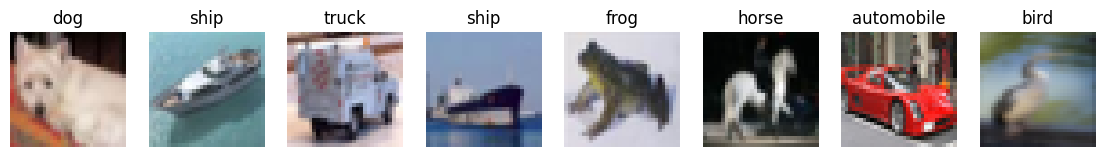

In [8]:
train_loader, val_loader = get_loaders()
xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)                         # expect [128, 3, 32, 32] and [128]
print(f'mean: {xb.mean(dim=(0, 2, 3))}, std: {xb.std(dim=(0, 2, 3))}')  # should be close to 0 and 1

classes = raw.classes
imgs = xb[:8] * std.view(3, 1, 1) + mean.view(3, 1, 1)   # undo normalization for display
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, img, lbl in zip(axes, imgs, yb[:8]):
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1)); ax.set_title(classes[lbl]); ax.axis('off')
plt.show()

# Task 1: Backpropogation
(a) Implement Linear, ReLU, and softmax cross-entropy with explicit `forward/backward` (no `autograd`), and assemble an MLP.<br/>
(b) Verify your gradients against `autograd` and against centred finite differences; report the relative errors. Use `torch`. allclose to check whether the gradients match. <br/>
(c) Train it with SGD on flattened `CIFAR-10` images; plot the loss and report validation accuracy. <br/>
(d) For a 10-layer MLP, plot the per-layer gradient norm at initialization with sigmoid and with ReLU. Explain.
